# Topic declaration

**Question:** How does the choice of single-wavelength versus multiwavelength nonlinear fitting affect the estimated apparent pKa of methyl orange and its associated fitting uncertainty?

**Data source:** Goto, S. Raw UV-vis absorption spectra of pH indicator dyes for singular-value analysis of overlapping chemical equilibria, Version 1. Mendeley Data, DOI 10.17632/jp2j9hz6v9.1. https://data.mendeley.com/datasets/jp2j9hz6v9/1, accessed 2026-11-08. File: `data/20160621MO-pH.xlsx`.

**Purpose of the next cell:** load the methyl orange spectra from a relative path and report their size, column names, and units.

**Scientific choice:** use the `in H2O` sheet, because the source page does not give the ethanol percentage for the `in EtOH` sheet. Read only columns B to N, which hold the wavelength and the 12 pH series. Column O holds 66 unlabeled numbers beside 400 to 534 nm that are not under a pH heading.

**Expected output:** 551 rows (one per wavelength, 250 to 800 nm), then `wavelength_nm` and the 12 pH values from 2.0 to 7.0 as column names, then the units.

In [1]:
import pandas as pd

data = pd.read_excel("data/20160621MO-pH.xlsx", sheet_name="in H2O", usecols="B:N")
data = data.rename(columns={data.columns[0]: "wavelength_nm"})
print(f"{len(data)} rows")
print(list(data.columns))
print("absorbance: AU (one column per pH); wavelength_nm: nm")

551 rows
['wavelength_nm', 2, 2.2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7]
absorbance: AU (one column per pH); wavelength_nm: nm


Dataset: 551 wavelengths by 12 pH values
Missing absorbance values: 0
Largest range across pH: 1.017 AU at 531 nm
Wavelengths from 350–650 nm with range > 0.1 AU: 203


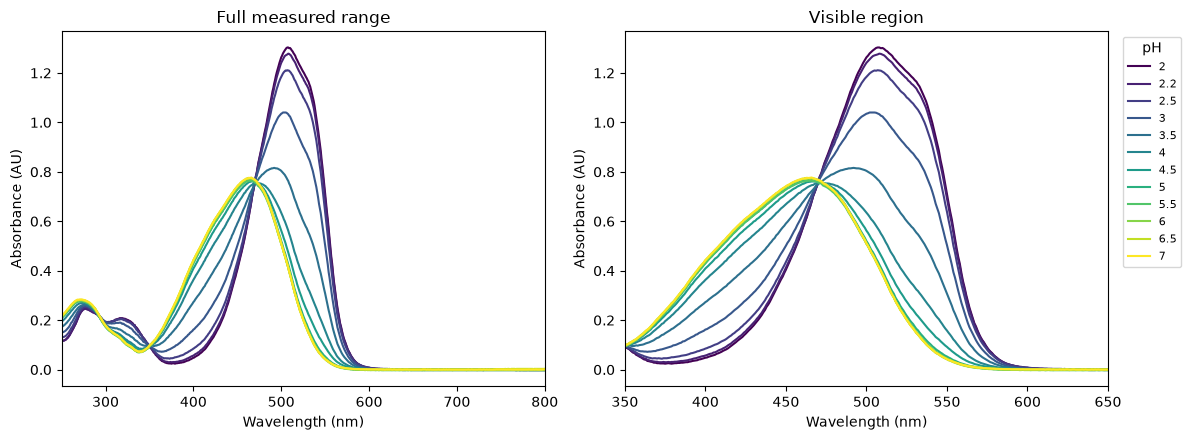

In [2]:
import numpy as np
import matplotlib.pyplot as plt

wavelength = data["wavelength_nm"].to_numpy(dtype=float)
ph = np.asarray(data.columns[1:], dtype=float)
absorbance = data.iloc[:, 1:].to_numpy(dtype=float)
spread = np.ptp(absorbance, axis=1)

print(f"Dataset: {absorbance.shape[0]} wavelengths by {absorbance.shape[1]} pH values")
print(f"Missing absorbance values: {np.isnan(absorbance).sum()}")
peak_index = np.argmax(spread)
print(f"Largest range across pH: {spread[peak_index]:.3f} AU at {wavelength[peak_index]:.0f} nm")
visible = (wavelength >= 350) & (wavelength <= 650)
print(f"Wavelengths from 350–650 nm with range > 0.1 AU: {np.sum(spread[visible] > 0.1)}")

colors = plt.cm.viridis(np.linspace(0, 1, len(ph)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for column, (condition, color) in enumerate(zip(ph, colors)):
    for ax in axes:
        ax.plot(wavelength, absorbance[:, column], color=color, label=f"{condition:g}")
axes[0].set_xlim(250, 800)
axes[0].set_title("Full measured range")
axes[1].set_xlim(350, 650)
axes[1].set_title("Visible region")
for ax in axes:
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Absorbance (AU)")
axes[1].legend(title="pH", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()


Absorbance changes with pH, with the largest change at 531 nm.

Smallest range in 450–490 nm: 470 nm
Absorbance range there: 0.750–0.768 AU
Spread across pH: 0.018 AU


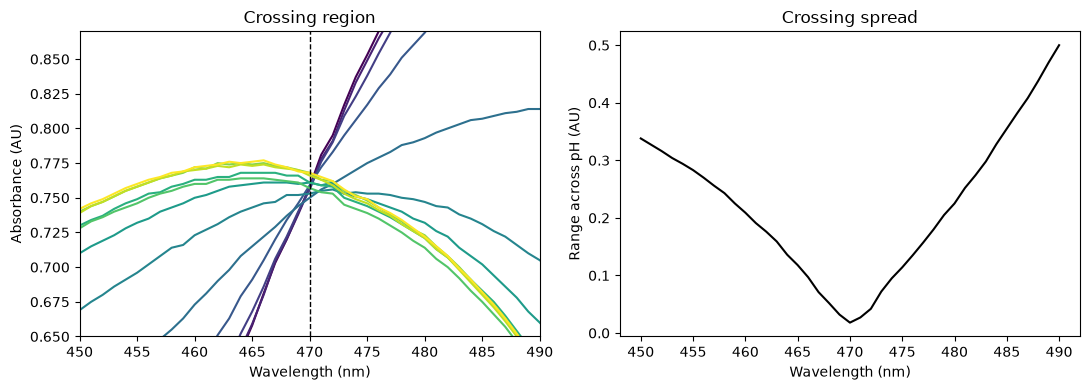

In [3]:
crossing_window = (wavelength >= 450) & (wavelength <= 490)
window_indices = np.flatnonzero(crossing_window)
crossing_index = window_indices[np.argmin(spread[crossing_window])]
print(f"Smallest range in 450–490 nm: {wavelength[crossing_index]:.0f} nm")
print(f"Absorbance range there: {absorbance[crossing_index].min():.3f}–{absorbance[crossing_index].max():.3f} AU")
print(f"Spread across pH: {spread[crossing_index]:.3f} AU")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for column, color in enumerate(colors):
    axes[0].plot(wavelength, absorbance[:, column], color=color)
axes[0].axvline(wavelength[crossing_index], color="black", linestyle="--", linewidth=1)
axes[0].set(xlim=(450, 490), ylim=(0.65, 0.87), xlabel="Wavelength (nm)", ylabel="Absorbance (AU)", title="Crossing region")
axes[1].plot(wavelength[crossing_window], spread[crossing_window], color="black")
axes[1].set(xlabel="Wavelength (nm)", ylabel="Range across pH (AU)", title="Crossing spread")
fig.tight_layout()
plt.show()


The spectra nearly intersect at 470 nm, where absorbance varies by 0.018 AU across the 12 pH conditions.

**Initial interpretation:**


The dataset contains 551 wavelengths and 12 pH conditions, with no missing absorbance values. The largest change across pH is 1.017 AU at 531 nm. Between 350 and 650 nm, 203 wavelengths change by more than 0.1 AU.

Within 450–490 nm, the smallest range occurs at 470 nm. Absorbance there runs from 0.750 to 0.768 AU, a spread of 0.018 AU. This is an approximate common crossing. It is consistent with the proposed two-state model, but the crossing alone cannot establish that only two species contribute.

No pKa has been fitted in this first analysis. The next analysis will compare a 531 nm fit with a shared-pKa fit over 350–650 nm, then examine residuals and sensitivity to leaving out individual pH conditions. Uncertainty must account for the lack of independent replicates and the dependence between wavelengths within a spectrum.

## Environment

Purpose: record the Python and package versions this notebook ran with, so the results can be reproduced from `uv.lock`. No scientific choice is made here. Expected output: one line per item, Python first.


In [4]:
import sys
from importlib.metadata import version

print(f"Python: {sys.version.split()[0]}")
for package in ["numpy", "pandas", "matplotlib", "openpyxl"]:
    print(f"{package}: {version(package)}")

Python: 3.14.7
numpy: 2.5.3
pandas: 3.0.6
matplotlib: 3.11.2
openpyxl: 3.1.5
